# Week 9 — Machine learning I: learning from examples

Companion notebook of the ninth lecture. **Supervised learning** builds a prediction rule from examples whose answers are known. We predict diamond prices (regression) and classify tumor cells (classification), split the data into training and test sets, choose a tree's depth by cross-validation, grow decision trees by hand, combine many trees into random forests and gradient boosting, judge a classifier by its confusion matrix and ROC curve, and finally rebuild the **2024 MCM Problem C** tennis-momentum model of Team 2409404.

**How to run**: Anaconda locally (`jupyter lab`), or Colab/Binder from the [course repository](https://github.com/liwt31/MathModel). Run cells in order with `Shift+Enter`. The whole notebook runs in about two minutes on a laptop.

**Note.** The exercises here and on the slides are **practice for yourself**, and they are **not** the graded assignments. Problem sets are released separately on Blackboard, with due dates.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:                                  # optional style file, ships with the course
    plt.style.use("mm.mplstyle")
except OSError:
    pass
plt.rcParams.update({"figure.figsize": (6.4, 4.0), "figure.dpi": 100, "legend.fontsize": 9,
                     "legend.framealpha": 0.9, "axes.titlesize": 11})

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, accuracy_score, confusion_matrix, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance

DATA = "https://raw.githubusercontent.com/liwt31/MathModel/refs/heads/2026/data/"
def load(file):
    try:
        return pd.read_csv(DATA + file)
    except Exception:                   # offline fallback: the repo's data/ folder
        return pd.read_csv("data/" + file)

rmse = lambda y, p: float(np.sqrt(mean_squared_error(y, p)))

## 1. The diamond data

53,940 round diamonds with their price in US dollars and nine measurements: the weight in **carat** (1 carat = 0.2 g), the quality of the **cut**, the **color** (D is colorless and best, J is the most yellow), the **clarity** (IF is internally flawless, I1 has visible inclusions), and the shape measurements depth (%), table (%), and the length, width, height `x`, `y`, `z` in mm. Each row is one **example**, the nine measurements are the **features**, and the price is the **label** we want to predict.

In [2]:
d = load("diamonds.csv")
print(d.shape)
d.head(6)

(53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48


Cut, color and clarity are words with a natural order. We turn each into an integer that respects the order (a larger number means better quality). Typing the words into the model as arbitrary codes would invent an order that is not there.

In [3]:
order = {"cut": ["Fair", "Good", "Very Good", "Premium", "Ideal"],
         "color": list("JIHGFED"),
         "clarity": ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]}
X = d[["carat", "cut", "color", "clarity", "depth", "table", "x", "y", "z"]].copy()
for col, levels in order.items():
    X[col] = X[col].map({v: i for i, v in enumerate(levels)})
y = d["price"]
print(X.head(3))
print("price from", y.min(), "to", y.max(), "dollars, median", y.median())

   carat  cut  color  clarity  depth  table     x     y     z
0   0.23    4      5        1   61.5   55.0  3.95  3.98  2.43
1   0.21    3      5        2   59.8   61.0  3.89  3.84  2.31
2   0.23    1      5        4   56.9   65.0  4.05  4.07  2.31
price from 326 to 18823 dollars, median 2401.0


## 2. Training set and test set

We hide 20% of the diamonds as a **test set** before any model sees them, train on the other 80%, and judge every model by its error on the hidden diamonds. The error measure is the root-mean-square error (RMSE) in dollars.

In [4]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=0)
print("training", len(Xtr), " test", len(Xte))

line = LinearRegression().fit(Xtr[["carat"]], ytr)
print(f"price ≈ {line.coef_[0]:.0f} × carat {line.intercept_:+.0f}")
print("line on carat   train RMSE", round(rmse(ytr, line.predict(Xtr[['carat']]))), " test RMSE", round(rmse(yte, line.predict(Xte[['carat']]))))
lin = LinearRegression().fit(Xtr, ytr)
print("all nine features train RMSE", round(rmse(ytr, lin.predict(Xtr))), " test RMSE", round(rmse(yte, lin.predict(Xte))))

training 43152  test 10788
price ≈ 7745 × carat -2248
line on carat   train RMSE 1552  test RMSE 1534
all nine features train RMSE 1221  test RMSE 1198


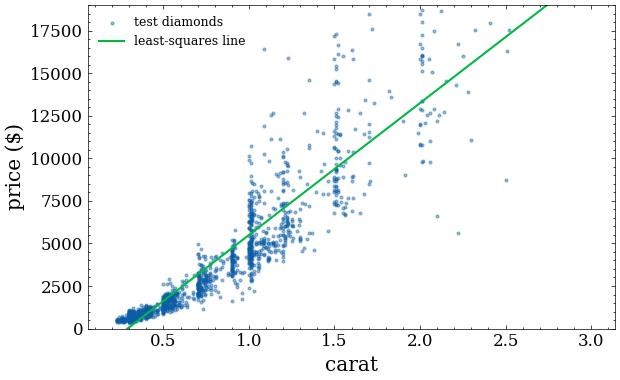

In [5]:
cc = np.linspace(0.2, 3, 200)
plt.scatter(Xte["carat"][:1500], yte[:1500], s=4, alpha=0.4, label="test diamonds")
plt.plot(cc, line.predict(pd.DataFrame({"carat": cc})), "C1", label="least-squares line")
plt.xlabel("carat"); plt.ylabel("price ($)"); plt.ylim(0, 19000); plt.legend(loc="upper left"); plt.tight_layout(); plt.show()

## 3. Overfitting and the choice of depth

A regression tree with more levels can follow the training data more closely. The training error keeps falling as the depth grows, while the test error falls, bottoms out, and rises again: the deep trees **overfit**.

 max depth  train RMSE  test RMSE  leaves
       1.0        2501       2481       2
       2.0        1660       1629       4
       3.0        1336       1317       8
       4.0        1158       1165      16
       6.0         852        866      64
       8.0         671        709     253
      10.0         536        636     947
      15.0         290        677   10515
      20.0         111        711   28801
       NaN           8        721   36797


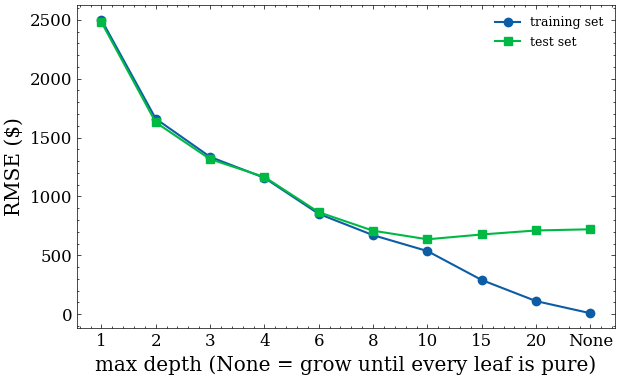

In [6]:
rows = []
for depth in [1, 2, 3, 4, 6, 8, 10, 15, 20, None]:
    t = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(Xtr, ytr)
    rows.append((depth, round(rmse(ytr, t.predict(Xtr))), round(rmse(yte, t.predict(Xte))), t.get_n_leaves()))
tab = pd.DataFrame(rows, columns=["max depth", "train RMSE", "test RMSE", "leaves"]); print(tab.to_string(index=False))
lab = [str(r[0]) for r in rows]
plt.plot(lab, tab["train RMSE"], "o-", label="training set"); plt.plot(lab, tab["test RMSE"], "s-", label="test set")
plt.xlabel("max depth (None = grow until every leaf is pure)"); plt.ylabel("RMSE ($)"); plt.legend(); plt.tight_layout(); plt.show()

Choosing the depth by looking at the test error would turn the test set into part of the training. **Five-fold cross-validation** chooses it from the training set alone: split the training set into five folds, train on four and measure on the fifth, rotate, and average the five errors.

In [7]:
kf = KFold(5, shuffle=True, random_state=0)
cv = {}
for depth in [2, 4, 6, 8, 10, 12, 15, None]:
    s = -cross_val_score(DecisionTreeRegressor(max_depth=depth, random_state=0), Xtr, ytr, cv=kf, scoring="neg_root_mean_squared_error")
    cv[depth] = s.mean(); print(f"depth {str(depth):>4}: fold RMSE {s.round(0)}  mean {s.mean():.0f}")
best = min(cv, key=cv.get); print("chosen depth", best)
t = DecisionTreeRegressor(max_depth=best, random_state=0).fit(Xtr, ytr)
print("test RMSE of the chosen tree, measured once:", round(rmse(yte, t.predict(Xte))))

depth    2: fold RMSE [1656. 1657. 1699. 1634. 1664.]  mean 1662


depth    4: fold RMSE [1166. 1145. 1199. 1143. 1164.]  mean 1163


depth    6: fold RMSE [847. 860. 895. 843. 878.]  mean 864


depth    8: fold RMSE [685. 705. 735. 683. 711.]  mean 704


depth   10: fold RMSE [632. 639. 662. 632. 639.]  mean 641


depth   12: fold RMSE [645. 648. 673. 654. 654.]  mean 655


depth   15: fold RMSE [701. 710. 731. 698. 719.]  mean 712


depth None: fold RMSE [752. 745. 787. 736. 742.]  mean 752
chosen depth 10
test RMSE of the chosen tree, measured once: 636


## 4. Growing a tree by hand

Six Ideal-cut diamonds of color G and clarity VS2. A tree's first split on carat puts a threshold between two neighboring diamonds and predicts the mean price on each side. It picks the threshold with the smallest sum of squared errors (SSE).

In [8]:
six = pd.DataFrame({"carat": [0.31, 0.52, 0.71, 1.01, 1.21, 1.51], "price": [574, 1586, 2762, 6295, 7996, 13163]})
x6, y6 = six.carat.values, six.price.values.astype(float)
print("no split: predict the mean", y6.mean(), " SSE", ((y6 - y6.mean())**2).sum())
for k in range(1, 6):
    L, R = y6[:k], y6[k:]
    sse = ((L - L.mean())**2).sum() + ((R - R.mean())**2).sum()
    print(f"carat <= {(x6[k-1] + x6[k]) / 2:.3f}: left mean {L.mean():7.1f}, right mean {R.mean():7.1f}, SSE {sse:12,.0f}")
# the full data's two-level tree on carat
t2 = DecisionTreeRegressor(max_depth=2).fit(Xtr[["carat"]], ytr)
print(export_text(t2, feature_names=["carat"]))

no split: predict the mean 5396.0  SSE 112600230.0
carat <= 0.415: left mean   574.0, right mean  6360.4, SSE   84,698,209
carat <= 0.615: left mean  1080.0, right mean  7554.0, SSE   56,716,662
carat <= 0.860: left mean  1640.7, right mean  9151.3, SSE   27,985,059
carat <= 1.110: left mean  2804.2, right mean 10579.5, SSE   31,994,213
carat <= 1.360: left mean  3842.6, right mean 13163.0, SSE   40,208,683
|--- carat <= 1.00
|   |--- carat <= 0.62
|   |   |--- value: [1053.50]
|   |--- carat >  0.62
|   |   |--- value: [3061.07]
|--- carat >  1.00
|   |--- carat <= 1.50
|   |   |--- value: [6138.51]
|   |--- carat >  1.50
|   |   |--- value: [12260.30]



For classification the tree measures how mixed a group is with the **Gini impurity** $G = 1 - \sum_k p_k^2$, where $p_k$ is the share of class $k$ in the group. The tumor data (569 cell samples, 212 malignant) shows the first split.

In [9]:
from sklearn.datasets import load_breast_cancer
bc = load_breast_cancer()
Xb = pd.DataFrame(bc.data, columns=bc.feature_names); yb = 1 - bc.target          # 1 = malignant, 0 = benign
a_tr, a_te, b_tr, b_te = train_test_split(Xb, yb, test_size=0.25, random_state=0, stratify=yb)
print("training", len(b_tr), "cells:", (b_tr == 0).sum(), "benign,", (b_tr == 1).sum(), "malignant; test", len(b_te))
two = ["worst radius", "worst concave points"]
tc = DecisionTreeClassifier(max_depth=2, random_state=0).fit(a_tr[two], b_tr)
print(export_text(tc, feature_names=two, show_weights=True))
gini = lambda n0, n1: 1 - (n0 / (n0 + n1))**2 - (n1 / (n0 + n1))**2
print(f"Gini at the root {gini(267, 159):.3f}; after the first split {gini(258, 25):.3f} (left) and {gini(9, 134):.3f} (right)")
for depth in [1, 2, 3, 4, 6, None]:
    t = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(a_tr[two], b_tr)
    print(f"depth {str(depth):>4}: train accuracy {accuracy_score(b_tr, t.predict(a_tr[two])):.3f}, test accuracy {accuracy_score(b_te, t.predict(a_te[two])):.3f}")

training 426 cells: 267 benign, 159 malignant; test 143
|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- weights: [246.00, 4.00] class: 0
|   |--- worst concave points >  0.14
|   |   |--- weights: [12.00, 21.00] class: 1
|--- worst radius >  16.80
|   |--- worst concave points <= 0.15
|   |   |--- weights: [9.00, 22.00] class: 1
|   |--- worst concave points >  0.15
|   |   |--- weights: [0.00, 112.00] class: 1

Gini at the root 0.468; after the first split 0.161 (left) and 0.118 (right)
depth    1: train accuracy 0.920, test accuracy 0.930
depth    2: train accuracy 0.941, test accuracy 0.930
depth    3: train accuracy 0.953, test accuracy 0.965
depth    4: train accuracy 0.974, test accuracy 0.930
depth    6: train accuracy 0.991, test accuracy 0.930
depth None: train accuracy 1.000, test accuracy 0.923


## 5. Ensembles: random forests and gradient boosting

A **random forest** trains many deep trees, each on a bootstrap sample (rows drawn with replacement) and with a random subset of features at every split, and averages their predictions. A bootstrap sample of $n$ rows contains about $1 - 1/e \approx 63\%$ of the distinct rows.

In [10]:
rng = np.random.default_rng(0)
print("share of distinct rows in a bootstrap sample:", np.mean([len(np.unique(rng.integers(0, 1000, 1000))) / 1000 for _ in range(200)]).round(3))
for n in [1, 5, 20, 100]:
    rf = RandomForestRegressor(n_estimators=n, random_state=0, n_jobs=-1).fit(Xtr, ytr)
    print(f"{n:4d} trees: test RMSE {rmse(yte, rf.predict(Xte)):.0f}")
rf = RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1).fit(Xtr, ytr)
print("100 trees: train RMSE", round(rmse(ytr, rf.predict(Xtr))))

share of distinct rows in a bootstrap sample: 0.633


   1 trees: test RMSE 742


   5 trees: test RMSE 590


  20 trees: test RMSE 549


 100 trees: test RMSE 536


100 trees: train RMSE 204


**Gradient boosting** adds small trees one at a time; each new tree is fitted to the errors (residuals) left by the trees before it, and its prediction is added with a learning rate $\eta$. Three rounds by hand on the six diamonds, with one-split trees and $\eta = 0.5$:

In [11]:
F = np.full(6, y6.mean()); eta = 0.5
for m in range(3):
    r = y6 - F
    best = min(range(1, 6), key=lambda k: ((r[:k] - r[:k].mean())**2).sum() + ((r[k:] - r[k:].mean())**2).sum())
    h = np.where(np.arange(6) < best, r[:best].mean(), r[best:].mean())
    F = F + eta * h
    print(f"round {m+1}: residuals {r.round(0)}, split after diamond {best}, new prediction {F.round(0)}, RMSE {np.sqrt(((y6 - F)**2).mean()):.0f}")
for n, lr in [(50, 0.1), (100, 0.1), (300, 0.1), (100, 1.0), (100, 0.01)]:
    g = GradientBoostingRegressor(n_estimators=n, learning_rate=lr, random_state=0).fit(Xtr, ytr)
    print(f"{n:5d} trees, learning rate {lr}: train RMSE {rmse(ytr, g.predict(Xtr)):6.0f}, test RMSE {rmse(yte, g.predict(Xte)):6.0f}")

round 1: residuals [-4822. -3810. -2634.   899.  2600.  7767.], split after diamond 3, new prediction [3518. 3518. 3518. 7274. 7274. 7274.], RMSE 2862
round 2: residuals [-2944. -1932.  -756.  -979.   722.  5889.], split after diamond 5, new prediction [ 2929.  2929.  2929.  6685.  6685. 10218.], RMSE 1728
round 3: residuals [-2355. -1343.  -167.  -390.  1311.  2945.], split after diamond 4, new prediction [ 2397.  2397.  2397.  6153.  7749. 11282.], RMSE 1135


   50 trees, learning rate 0.1: train RMSE    706, test RMSE    725


  100 trees, learning rate 0.1: train RMSE    598, test RMSE    618


  300 trees, learning rate 0.1: train RMSE    525, test RMSE    561


  100 trees, learning rate 1.0: train RMSE    509, test RMSE    594


  100 trees, learning rate 0.01: train RMSE   1841, test RMSE   1842


## 6. Judging a classifier

A random forest on all 30 tumor measurements, judged on the 143 held-out cells. Always answering "benign" would already be right on 63% of them, so accuracy alone says little. The **confusion matrix** counts the four kinds of answers; **precision** is the share of predicted malignant cells that are malignant, **recall** the share of malignant cells that are found.

always benign would score 0.629
threshold 0.5: TN 85 FP 5 FN 1 TP 52; accuracy 0.958, precision 0.912, recall 0.981
threshold 0.3: TN 81 FP 9 FN 1 TP 52; accuracy 0.930, precision 0.852, recall 0.981
threshold 0.2: TN 78 FP 12 FN 1 TP 52; accuracy 0.909, precision 0.812, recall 0.981
threshold 0.1: TN 71 FP 19 FN 1 TP 52; accuracy 0.860, precision 0.732, recall 0.981
AUC 0.9885


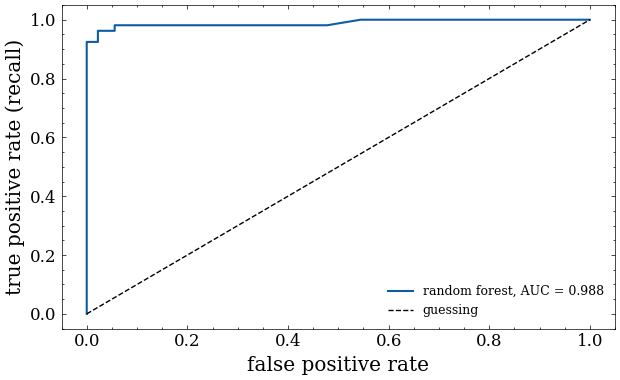

In [12]:
clf = RandomForestClassifier(n_estimators=200, random_state=0).fit(a_tr, b_tr)
p = clf.predict_proba(a_te)[:, 1]
print("always benign would score", round((b_te == 0).mean(), 3))
for th in [0.5, 0.3, 0.2, 0.1]:
    pr = (p >= th).astype(int); tn, fp, fn, tp = confusion_matrix(b_te, pr).ravel()
    print(f"threshold {th}: TN {tn} FP {fp} FN {fn} TP {tp}; accuracy {accuracy_score(b_te, pr):.3f}, "
          f"precision {precision_score(b_te, pr):.3f}, recall {recall_score(b_te, pr):.3f}")
fpr, tpr, _ = roc_curve(b_te, p)
print("AUC", round(roc_auc_score(b_te, p), 4))
plt.plot(fpr, tpr, label=f"random forest, AUC = {roc_auc_score(b_te, p):.3f}"); plt.plot([0, 1], [0, 1], "k--", lw=1, label="guessing")
plt.xlabel("false positive rate"); plt.ylabel("true positive rate (recall)"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 7. Feature importance

The forest's built-in (impurity) importance measures how much each feature's splits reduce the error. **Permutation importance** shuffles one feature in the test set and measures how much the test error rises. Strongly correlated features share the credit: carat and the width `y` carry nearly the same information.

In [13]:
print("impurity importance:", dict(zip(X.columns, rf.feature_importances_.round(3))))
pi = permutation_importance(rf, Xte.iloc[:2000], yte.iloc[:2000], n_repeats=3, random_state=0, scoring="neg_root_mean_squared_error", n_jobs=-1)
print("RMSE increase when shuffled ($):", dict(zip(X.columns, pi.importances_mean.round(0))))
print("correlation of carat with x, y, z:", X[["carat", "x", "y", "z"]].corr().iloc[0, 1:].round(3).to_dict())
rf3 = RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1).fit(Xtr.drop(columns=["x", "y", "z"]), ytr)
print("without x, y, z: test RMSE", round(rmse(yte, rf3.predict(Xte.drop(columns=['x', 'y', 'z'])))),
      " importance", dict(zip(Xtr.columns.drop(["x", "y", "z"]), rf3.feature_importances_.round(3))))

impurity importance: {'carat': np.float64(0.565), 'cut': np.float64(0.002), 'color': np.float64(0.032), 'clarity': np.float64(0.064), 'depth': np.float64(0.003), 'table': np.float64(0.002), 'x': np.float64(0.005), 'y': np.float64(0.321), 'z': np.float64(0.005)}


RMSE increase when shuffled ($): {'carat': np.float64(3569.0), 'cut': np.float64(21.0), 'color': np.float64(834.0), 'clarity': np.float64(1072.0), 'depth': np.float64(6.0), 'table': np.float64(18.0), 'x': np.float64(70.0), 'y': np.float64(1468.0), 'z': np.float64(100.0)}
correlation of carat with x, y, z: {'x': 0.975, 'y': 0.952, 'z': 0.953}


without x, y, z: test RMSE 543  importance {'carat': np.float64(0.883), 'cut': np.float64(0.003), 'color': np.float64(0.033), 'clarity': np.float64(0.068), 'depth': np.float64(0.008), 'table': np.float64(0.004)}


## 8. Case study: 2024 MCM C, momentum in tennis (Team 2409404)

The problem gives every point of the 31 men's singles matches of Wimbledon 2023 after the second round: 7,284 points and 46 columns. Team 2409404 scores each player's **momentum** at point $i$ as a sum over the last $\beta = 5$ points (their Eq. 1),

$$M_i = \sum_{k=i-\beta+1}^{i}\bigl[GA_k + SC_k + (\alpha + 1)\,SER_k + PV_k + BPW_k + ACE_k + NPW_k + W_k - UE_k - DF_k\bigr],\qquad \alpha = 0.68,$$

labels each point 1 when player 1's momentum is larger and 0 otherwise (their Eq. 7), trains an XGBoost classifier on the 43 columns of the first 30 matches, and tests it on the final (334 points). The paper does not spell out how the state columns (games, score) enter a five-point sum, so the rebuild below uses one reading: each bracket term is the player's own 0/1 event column for that point (game won, point won, serving, break point won, ace, net point won, winner, unforced error, double fault), with $SC$ read as the point-won indicator. **Reproductions need not match**; the label changes with the reading of each term, and with it every metric.

In [14]:
w = load("Wimbledon_featured_matches.csv")
print(w.shape, "points in", w.match_id.nunique(), "matches")
final = w.match_id == "2023-wimbledon-1701"
print("the final:", w[final].player1.iloc[0], "vs", w[final].player2.iloc[0], "-", final.sum(), "points")
print("share of points won by the server:", round((w.point_victor == w.server).mean(), 3))

alpha, beta = 0.68, 5
def momentum(g):
    out = {}
    for p in (1, 2):
        s = ((g.game_victor == p).astype(int) + (g.point_victor == p).astype(int) + (alpha + 1) * (g.server == p)
             + (g.point_victor == p).astype(int) + g[f"p{p}_break_pt_won"] + g[f"p{p}_ace"] + g[f"p{p}_net_pt_won"]
             + g[f"p{p}_winner"] - g[f"p{p}_unf_err"] - g[f"p{p}_double_fault"])
        out[p] = s.rolling(beta, min_periods=1).sum()          # within one match only
    return pd.DataFrame({"m1": out[1], "m2": out[2]}, index=g.index)
M = pd.concat([momentum(g) for _, g in w.groupby("match_id")])
w["lead"] = (M.m1 > M.m2).astype(int)
print("ties in our reading:", int((M.m1 == M.m2).sum()), "; label 1 on the final:", int(w[final].lead.sum()), "of", final.sum())

(7284, 46) points in 31 matches
the final: Carlos Alcaraz vs Novak Djokovic - 334 points
share of points won by the server: 0.673
ties in our reading: 0 ; label 1 on the final: 149 of 334


In [15]:
def tosec(t):
    h, m, s = map(int, t.split(":")); return 3600 * h + 60 * m + s
F43 = w.drop(columns=["match_id", "player1", "player2", "lead"]).copy()
F43["elapsed_time"] = w.elapsed_time.map(tosec)
for c in F43.columns:                                      # text columns -> integer codes, gaps -> 0 (as in the paper)
    if F43[c].dtype == object:
        F43[c] = F43[c].fillna("0").astype(str).astype("category").cat.codes
F43 = F43.fillna(0)
print(F43.shape[1], "features")
try:
    from xgboost import XGBClassifier
    model = XGBClassifier(random_state=0)
except ImportError:                                        # fallback if xgboost is not installed
    from sklearn.ensemble import GradientBoostingClassifier
    model = GradientBoostingClassifier(random_state=0)
model.fit(F43[~final], w.lead[~final])
q = model.predict_proba(F43[final])[:, 1]
tn, fp, fn, tp = confusion_matrix(w.lead[final], q >= 0.5).ravel()
print(f"held-out final, our rebuild : accuracy {accuracy_score(w.lead[final], q >= 0.5):.4f}, AUC {roc_auc_score(w.lead[final], q):.3f}, TN {tn} FP {fp} FN {fn} TP {tp}")
print("held-out final, the paper   : accuracy 0.6916, AUC 0.75, TN 117 FP 37 FN 66 TP 114")
imp = pd.Series(model.feature_importances_, F43.columns); print((100 * imp / imp.max()).sort_values(ascending=False).head(8).round(1))

43 features


held-out final, our rebuild : accuracy 0.8982, AUC 0.955, TN 172 FP 13 FN 21 TP 128
held-out final, the paper   : accuracy 0.6916, AUC 0.75, TN 117 FP 37 FN 66 TP 114
server          100.000000
point_victor     66.800003
game_victor      50.299999
p2_score         36.500000
p1_score         32.099998
p1_break_pt      25.299999
p1_ace           21.000000
p2_break_pt      19.700001
dtype: float32


Our label agrees with the predictions far more often than the paper's. Two facts explain much of it in this reading: the label is a fixed function of the current and previous four rows of the very columns that serve as features, and serving carries the largest weight in Eq. 1, so `server` tops our importance list where the paper's top features are the break points and the point winner. The sensitivity to the reading is the lesson: write down every term of a feature or label precisely enough that someone else could rebuild it.

**Split by match or by point?** The paper keeps whole matches apart. Splitting the 7,284 points at random instead puts neighboring points of the same match on both sides, and the five-point windows overlap across the split:

In [16]:
a, b_, c, e = train_test_split(F43, w.lead, test_size=334 / len(w), random_state=0)
model.fit(a, c); print("random point split: test accuracy", round(accuracy_score(e, model.predict(b_)), 4))
# the runs test of their Task 2 on the pooled point-winner sequence
s = w.point_victor.values; m1, m2 = (s == 1).sum(), (s == 2).sum(); r = 1 + (s[1:] != s[:-1]).sum()
E = 2 * m1 * m2 / (m1 + m2) + 1; V = 2 * m1 * m2 * (2 * m1 * m2 - m1 - m2) / ((m1 + m2)**2 * (m1 + m2 - 1))
print(f"runs test: {r} runs, {E:.1f} expected under randomness, Z = {(r - E) / np.sqrt(V):.3f} (paper: Z = -5.613)")

random point split: test accuracy 0.9012
runs test: 3402 runs, 3641.4 expected under randomness, Z = -5.613 (paper: Z = -5.613)


## Practice exercises

**These are practice for yourself, and they are not the graded assignments.** Problem sets are released separately on Blackboard, with due dates.

1. **One more feature.** Fit the least-squares line on `carat` and `clarity` together. How much does the test RMSE drop compared with carat alone?
2. **Choose the forest's size.** Use five-fold cross-validation on the training set to choose `min_samples_leaf` of a random forest from 1, 5, 20. Report the test RMSE of the chosen forest once.
3. **Boosting by hand.** Continue the six-diamond boosting example for two more rounds. Does the training RMSE keep falling? What happens with $\eta = 1$?
4. **A safer threshold.** For the tumor forest, find the largest threshold that still finds every malignant cell in the test set. What is the precision there?
5. **Correlated features.** Add a copy of `carat` with a little noise to the diamond features and retrain the forest. How is the importance shared between the two copies?
6. **Momentum, other readings.** Change the reading of $SC_k$ in the case to the number of games won in the set so far, rebuild the label, and retrain. How do the accuracy on the final and the top features change?
